# Sleep Quality: Predicting Sleep Efficiency with a Mamdani FIS

Sleep efficiency is defined as

$$\text{SE}(\%) = \frac{\text{Total Sleep Time}}{\text{Time in Bed}} \times 100, \qquad \text{Time in Bed} = \text{Sleep Latency} + \text{TST} + \text{WASO}$$

The FIS therefore uses the three direct determinants of this ratio that are available in the Whoop dataset:

| Input | Role in the formula | Pearson *r* with `sleep_efficiency` |
|---|---|---|
| `sleep_hours` | Total Sleep Time (numerator) | +0.545 |
| `time_to_fall_asleep_min` | Sleep-onset latency (awake time in bed) | −0.325 |
| `wake_ups` | Fragmentation / wake after sleep onset | −0.328 |

The earlier version used `hrv` and `day_strain` (r ≈ 0.017 and r ≈ 0.000). Those measure autonomic state and exertion, not time in bed, and gave R² < 0. The sleep-stage columns (light/REM/deep) add up to `sleep_hours`, so they would only add multicollinearity and enlarge the rule base (3³ = 27 → 3⁵ = 243 rules).

## Imports

In [1]:
import sys
import os
import pandas as pd
import numpy as np
from skfuzzy.control import Rule
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from preprocessor import clean_missing_values
from mamdani_engine import GenericMamdaniEngine
from evaluation import (evaluate_regression, plot_regression_results, plot_membership_functions, plot_control_surface, plot_data_distributions, plot_universe_percentiles)

## Data Preprocessing

In [2]:
# File paths
raw_path = '../data/raw/whoop_fitness_dataset_100k.csv'
processed_path = '../data/processed/whoop_clean.csv'

input_features = ['sleep_hours', 'time_to_fall_asleep_min', 'wake_ups']
target = 'sleep_efficiency'
# hrv / day_strain are kept only to reproduce the previous FIS as a baseline
baseline_features = ['hrv', 'day_strain']
selected_cols = input_features + baseline_features + [target]

# Rebuild the cached file if it is missing or was saved with other columns
cache_ok = os.path.exists(processed_path) and list(pd.read_csv(processed_path, nrows=0).columns) == selected_cols
if not cache_ok:
    print("Loading raw data and applying general preprocessing...")
    df_raw = pd.read_csv(raw_path)
    df_subset = df_raw[selected_cols].copy()
    df_clean = clean_missing_values(df_subset, subset_columns=selected_cols)
    os.makedirs(os.path.dirname(processed_path), exist_ok=True)
    df_clean.to_csv(processed_path, index=False)
    print(f"Clean dataset saved to: {processed_path}")
else:
    print("Loading preprocessed dataset...")
    df_clean = pd.read_csv(processed_path)

print(f"Dataset shape: {df_clean.shape}")
print('wake_ups value counts:', df_clean['wake_ups'].value_counts().sort_index().to_dict())

# Input conditioning: 3+ wake-ups are ~1% of nights and all mean "many",
# so wake_ups is clipped to [0, 2] to keep the universe focused on the data.
df_clean['wake_ups'] = df_clean['wake_ups'].clip(0, 2)

# Hold-out split: everything (universes, rule consequents) is calibrated on train only
df_train, df_test = train_test_split(df_clean, test_size=0.2, random_state=42)
print(f"Train: {len(df_train)} rows | Test: {len(df_test)} rows")
df_train.head()

Loading preprocessed dataset...
Dataset shape: (100000, 6)
wake_ups value counts: {0: 72762, 1: 21687, 2: 4613, 3: 791, 4: 131, 5: 15, 7: 1}
Train: 80000 rows | Test: 20000 rows


,sleep_hours,time_to_fall_asleep_min,wake_ups,hrv,day_strain,sleep_efficiency
75220,8.02,5.0,0,53.8,10.44,90.5
48955,6.45,5.0,2,147.9,2.45,70.0
44966,6.50,5.0,0,60.5,15.09,86.6
13568,7.97,5.0,1,123.7,5.87,88.4
92727,7.03,5.2,0,58.8,11.35,75.3


## Data Distribution Analysis & Universe Calibration

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
sleep_hours,80000.0,7.30,0.97,4.0,4.75,5.49,6.65,7.46,8.02,8.64,9.02,9.91
time_to_fall_asleep_min,80000.0,5.57,2.19,5.0,5.00,5.00,5.00,5.00,5.00,9.00,16.10,51.30
wake_ups,80000.0,0.33,0.57,0.0,0.00,0.00,0.00,0.00,1.00,2.00,2.00,2.00
sleep_efficiency,80000.0,82.90,10.20,50.0,54.30,63.50,76.50,85.00,90.50,96.60,100.00,100.00


Sleep hours universe: [4.0, 9.91]
Latency universe: [5.0, 51.3]  (share of nights at the 5-min floor: 85.7%)
--- Mean sleep efficiency by sleep hours (rows) x latency (columns) ---


time_to_fall_asleep_min,"(0, 5]","(5, 10]","(10, 60]"
sleep_hours,,,
"(0, 6]",74.5,69.0,65.1
"(6, 7]",79.1,73.1,68.6
"(7, 8]",86.2,78.2,72.9
"(8, 11]",89.2,82.8,76.6


--- Feature Distributions Analysis ---


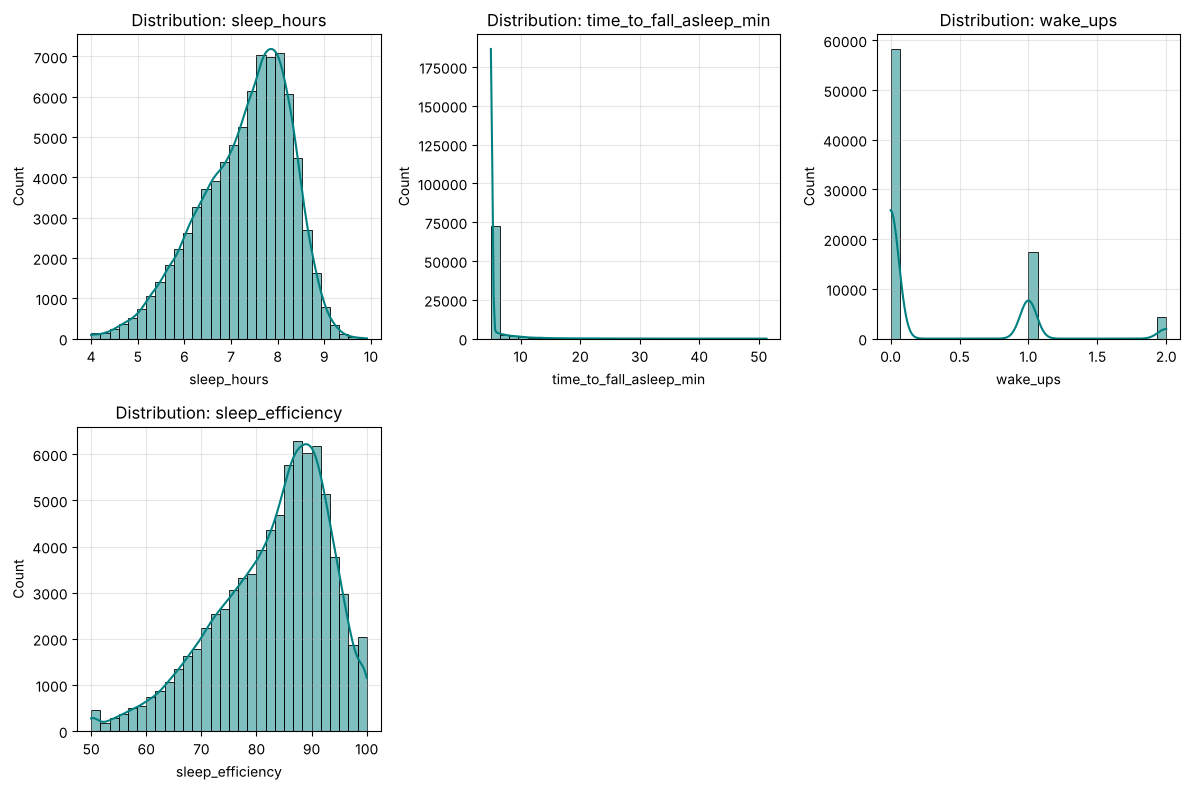

--- Target Consequent Percentile Calibration ---


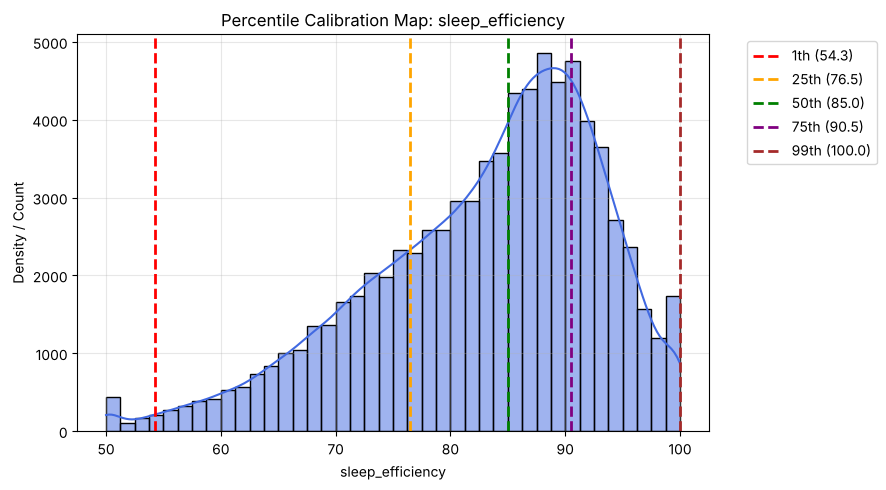

In [3]:
# Statistical bounds and percentiles from the training set
pct = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
display(df_train[input_features + [target]].describe(percentiles=pct).T.round(2))

sleep_min, sleep_max = float(df_train['sleep_hours'].min()), float(df_train['sleep_hours'].max())
lat_min, lat_max = float(df_train['time_to_fall_asleep_min'].min()), float(df_train['time_to_fall_asleep_min'].max())
eff_min, eff_max = 50.0, 100.0
print(f'Sleep hours universe: [{sleep_min}, {sleep_max}]')
print(f'Latency universe: [{lat_min}, {lat_max}]  (share of nights at the 5-min floor: '
      f"{(df_train['time_to_fall_asleep_min'] <= 5.0).mean():.1%})")

# Mean efficiency on a coarse grid: the shape the rule base has to reproduce
grid = df_train.groupby([
    pd.cut(df_train['sleep_hours'], [0, 6, 7, 8, 11]),
    pd.cut(df_train['time_to_fall_asleep_min'], [0, 5, 10, 60]),
], observed=True)[target].mean().unstack().round(1)
print('--- Mean sleep efficiency by sleep hours (rows) x latency (columns) ---')
display(grid)

print('--- Feature Distributions Analysis ---')
plot_data_distributions(df_train, columns=input_features + [target])

print('--- Target Consequent Percentile Calibration ---')
plot_universe_percentiles(df_train, target_col=target, percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])

## Mamdani FIS Configuration & Membership Functions

- **`sleep_hours`**: *short* below ~6 h, *adequate* around 7 h, *long* from ~8 h (5th / 50th / 95th percentiles: 5.5 / 7.5 / 8.6 h).
- **`time_to_fall_asleep_min`**: more than 75% of nights sit exactly at the 5-min floor, so *short* is a narrow shoulder at 5–5.5 min. *Moderate* peaks at 9 min (the 95th percentile) and *long* covers the tail.
- **`wake_ups`**: integer counts 0 / 1 / 2+ map to *few* / *medium* / *many*.
- **`sleep_efficiency`**: five triangular terms centered on the efficiency levels observed in the data (≈64, 69, 76, 83, 89 %). Wide shoulders reaching 50 and 100 would pull the centroid toward the middle of the range.

Output term centers: {'poor': 62.7, 'below_average': 69.0, 'average': 76.0, 'good': 83.0, 'excellent': 89.0}
--- Generare Grafice Funcții de Apartenență (Antecedente) ---


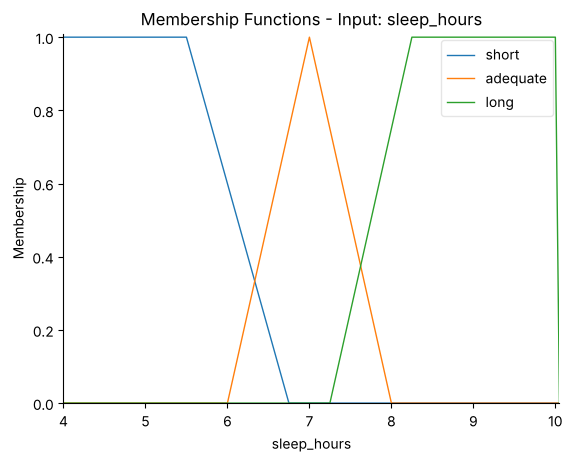

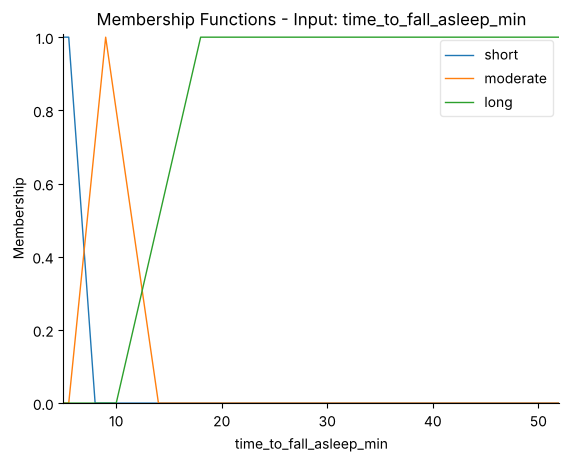

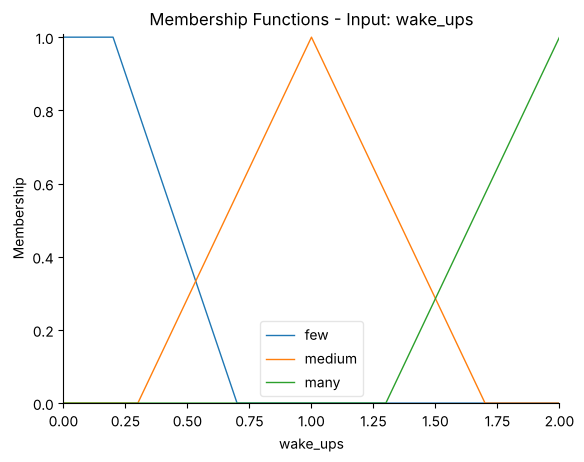

--- Generare Grafice Funcții de Apartenență (Consecvent) ---


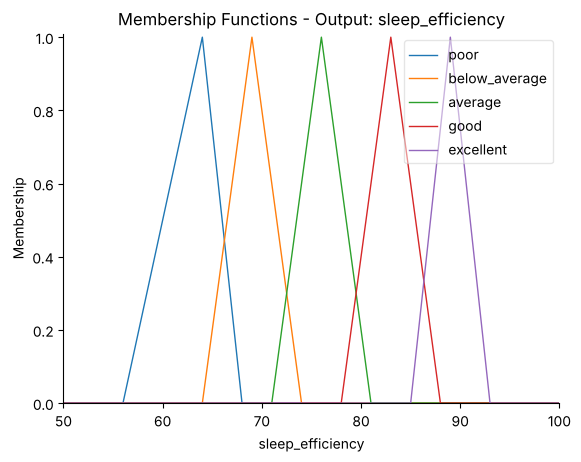

In [4]:
def build_fis(defuzzify_method='centroid'):
    fis = GenericMamdaniEngine()
    fis.add_antecedent(
        'sleep_hours',
        np.arange(4.0, 10.0 + 0.05, 0.05),
        {
            'short': [4.0, 4.0, 5.5, 6.75],
            'adequate': [6.0, 7.0, 8.0],
            'long': [7.25, 8.25, 10.0, 10.0]
        }
    )
    fis.add_antecedent(
        'time_to_fall_asleep_min',
        np.arange(5.0, 52.0 + 0.5, 0.5),
        {
            'short': [5.0, 5.0, 5.5, 8.0],
            'moderate': [5.5, 9.0, 14.0],
            'long': [10.0, 18.0, 52.0, 52.0]
        }
    )
    fis.add_antecedent(
        'wake_ups',
        np.arange(0.0, 2.0 + 0.05, 0.05),
        {
            'few': [0.0, 0.0, 0.2, 0.7],
            'medium': [0.3, 1.0, 1.7],
            'many': [1.3, 2.0, 2.0, 2.0]
        }
    )
    fis.add_consequent(
        'sleep_efficiency',
        np.arange(eff_min, eff_max + 0.25, 0.25),
        {
            'poor': [56.0, 64.0, 68.0],
            'below_average': [64.0, 69.0, 74.0],
            'average': [71.0, 76.0, 81.0],
            'good': [78.0, 83.0, 88.0],
            'excellent': [85.0, 89.0, 93.0]
        },
        defuzzify_method=defuzzify_method
    )
    return fis

fis = build_fis()
print('Output term centers:', {k: round(v, 1) for k, v in fis.term_centers(target).items()})
plot_membership_functions(fis)

## IF-THEN Rules Definition

### Expert rule base (27 rules)
Starting level from sleep hours (long → *excellent*, adequate → *good*, short → *below_average*). Each step up in latency or in wake-ups lowers the outcome by one level, never below *poor*.

In [5]:
levels = ['poor', 'below_average', 'average', 'good', 'excellent']
sleep_base = {'short': 1, 'adequate': 3, 'long': 4}
latency_penalty = {'short': 0, 'moderate': 1, 'long': 2}
wake_penalty = {'few': 0, 'medium': 1, 'many': 2}

# Rule matrix keyed wake_ups -> sleep_hours -> latency
rule_matrix = {
    wake: {
        sleep: {lat: levels[max(0, sleep_base[sleep] - latency_penalty[lat] - wake_penalty[wake])]
                for lat in latency_penalty}
        for sleep in sleep_base
    }
    for wake in wake_penalty
}

table_data = []
for wake_level, sleep_dict in rule_matrix.items():
    for sleep_level, lat_dict in sleep_dict.items():
        for lat_level, outcome in lat_dict.items():
            table_data.append({
                'sleep_hours': sleep_level,
                'time_to_fall_asleep_min': lat_level,
                'wake_ups': wake_level,
                target: outcome,
            })
expert_table = pd.DataFrame(table_data)
expert_rules = {tuple(r[c] for c in input_features): r[target] for _, r in expert_table.iterrows()}

pd.set_option('display.max_rows', None)
expert_table.index = expert_table.index + 1
expert_table.index.name = 'Rule'
expert_table

,sleep_hours,time_to_fall_asleep_min,wake_ups,sleep_efficiency
Rule,,,,
1,short,short,few,below_average
2,short,moderate,few,poor
3,short,long,few,poor
4,adequate,short,few,good
5,adequate,moderate,few,average
6,adequate,long,few,below_average
7,long,short,few,excellent
8,long,moderate,few,good
9,long,long,few,average


### Data-driven rule base (Wang–Mendel style)
For each of the 27 antecedent combinations, the engine computes the firing strength (AND = min) on every **training** row. It takes the firing-weighted mean of `sleep_efficiency` and assigns the output term whose center is closest to that mean. Rules with almost no support (sum of firing strengths < 5) keep the expert consequent. The rules stay readable IF-THEN statements, but each consequent is now backed by data.

In [6]:
learned_table = fis.learn_rule_consequents(
    df_train, input_features, target, min_support=5.0, default_rules=expert_rules
)
learned_table.index = learned_table.index + 1
learned_table.index.name = 'Rule'
learned_table['expert'] = [expert_rules[tuple(r[c] for c in input_features)] for _, r in learned_table.iterrows()]
learned_table['changed'] = np.where(learned_table[target] != learned_table['expert'], '*', '')
display(learned_table.round(1))
print(f"{(learned_table['changed'] == '*').sum()} of {len(learned_table)} consequents differ from the expert matrix")

rules = fis.rules_from_table(learned_table, input_features, target)
fis.build_system(rules)
print(f"Mamdani control system successfully built with {len(rules)} rules!")

,sleep_hours,time_to_fall_asleep_min,wake_ups,support,weighted_mean,sleep_efficiency,source,expert,changed
Rule,,,,,,,,,
1,short,short,few,5892.8,76.8,average,data,below_average,*
2,short,short,medium,2688.0,72.6,average,data,poor,*
3,short,short,many,910.9,68.7,below_average,data,poor,*
4,short,moderate,few,775.9,70.6,below_average,data,poor,*
5,short,moderate,medium,461.2,67.9,below_average,data,poor,*
6,short,moderate,many,177.9,65.1,poor,data,poor,
7,short,long,few,300.2,66.3,below_average,data,poor,*
8,short,long,medium,202.8,63.7,poor,data,poor,
9,short,long,many,99.3,62.3,poor,data,poor,


13 of 27 consequents differ from the expert matrix
Mamdani control system successfully built with 27 rules!


## Running Inference on the Held-out Test Set

In [7]:
# Random i.i.d. sample of the held-out test set (scikit-fuzzy runs row by row)
df_sample = df_test.sample(2000, random_state=42).copy()
y_true = df_sample[target].values

print("Running fuzzy inference on held-out data...")
y_pred = fis.predict_dataset(df_sample, input_features)
print(f"Inference complete for {len(y_pred)} samples ({fis.fallback_count} fallback predictions with no rule fired).")

Running fuzzy inference on held-out data...


Inference complete for 2000 samples (0 fallback predictions with no rule fired).


## Evaluation and Visualization

--- Quantitative Error Metrics Table (held-out test sample) ---


,Metric,Value
0,MAE (Mean Absolute Error),6.282920
1,MSE (Mean Squared Error),64.345221
2,RMSE (Root Mean Squared Error),8.021547
3,R2 Score,0.390739


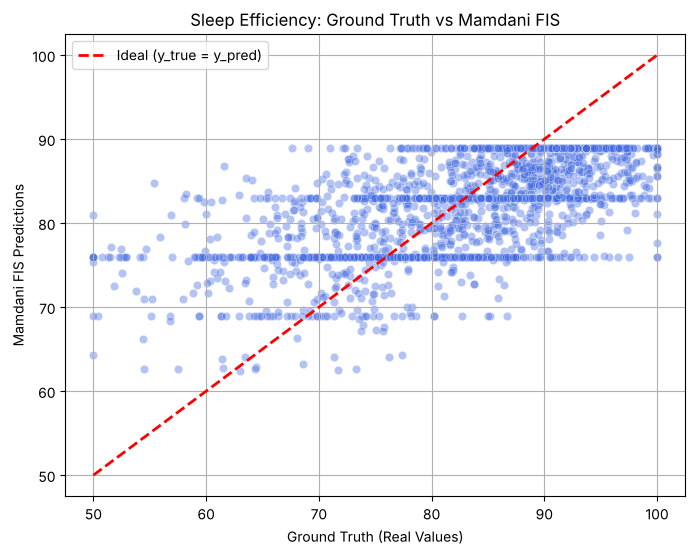

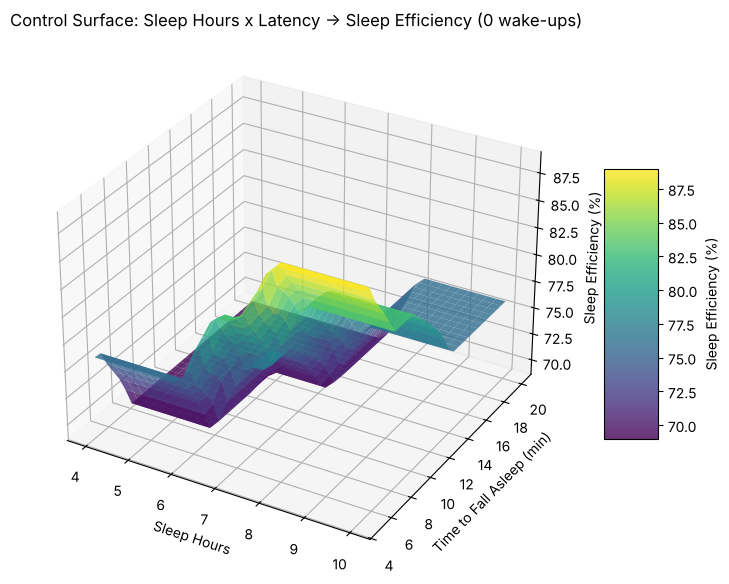

In [8]:
# 1. Quantitative Error Table
metrics_df = evaluate_regression(y_true, y_pred)
print("--- Quantitative Error Metrics Table (held-out test sample) ---")
display(metrics_df)

# 2. Regression Scatter Plot (Real vs Predicted)
plot_regression_results(y_true, y_pred, title='Sleep Efficiency: Ground Truth vs Mamdani FIS')

# 3. 3D Control Surface Plot (no wake-ups)
plot_control_surface(
    fis.simulation, 'sleep_hours', 'time_to_fall_asleep_min', target,
    x_range=(4.0, 10.0), y_range=(5.0, 20.0),
    fixed_inputs={'wake_ups': 0.0},
    labels=('Sleep Hours', 'Time to Fall Asleep (min)', 'Sleep Efficiency (%)'),
    title='Control Surface: Sleep Hours x Latency -> Sleep Efficiency (0 wake-ups)',
)

## Baseline Comparison

All models are scored on the same held-out sample:
- **Mean predictor**: always predicts the training mean (R² = 0 by definition).
- **Linear regression**: fitted on the same three inputs.
- **Previous FIS**: the HRV / day strain / wake-ups system from the earlier version.
- **Expert FIS** and **data-driven FIS**: the new inputs with the hand-written and the learned rule base.
- **Centroid vs bisector** defuzzification for the data-driven FIS.
- **Binned lookup table**: mean efficiency in fine bins of the three inputs. This approximates the best any model can do with these inputs.

In [9]:
def scores(name, pred):
    m = evaluate_regression(y_true, pred).set_index('Metric')['Value']
    return {'Model': name, 'MAE': m.iloc[0], 'RMSE': m.iloc[2], 'R2': m.iloc[3]}

results = [scores('Mean predictor', np.full(len(y_true), df_train[target].mean()))]

lin = LinearRegression().fit(df_train[input_features], df_train[target])
results.append(scores('Linear regression (3 inputs)', lin.predict(df_sample[input_features])))

# Previous FIS: hrv / day_strain / wake_ups with the earlier membership functions and rules
old = GenericMamdaniEngine()
old.add_antecedent('hrv', np.arange(20, 151, 1), {'low': [20.0, 20.0, 45.0, 65.0], 'medium': [45.0, 75.0, 105.0], 'high': [85.0, 115.0, 150.0, 150.0]})
old.add_antecedent('day_strain', np.arange(0, 21.5, 0.5), {'low': [0.0, 0.0, 5.0, 8.0], 'medium': [6.0, 11.0, 15.0], 'high': [13.0, 17.0, 21.0, 21.0]})
old.add_antecedent('wake_ups', np.arange(0, 8, 0.1), {'few': [0.0, 0.0, 0.2, 0.7], 'medium': [0.4, 1.0, 1.6], 'many': [1.3, 2.0, 7.0, 7.0]})
old.add_consequent('sleep_efficiency', np.arange(50, 101, 0.5), {'poor': [50.0, 50.0, 65.0, 70.0], 'below_average': [68.0, 73.0, 77.0], 'average': [74.0, 78.0, 82.0], 'good': [80.0, 83.5, 87.0], 'excellent': [85.0, 88.0, 95.0, 95.0]})
old_matrix = {  # wake -> hrv -> strain
    'few':    {'low': ['below_average', 'average', 'below_average'], 'medium': ['average', 'good', 'average'], 'high': ['good', 'excellent', 'good']},
    'medium': {'low': ['poor', 'below_average', 'poor'], 'medium': ['below_average', 'average', 'below_average'], 'high': ['average', 'good', 'average']},
    'many':   {'low': ['poor', 'poor', 'poor'], 'medium': ['poor', 'below_average', 'poor'], 'high': ['below_average', 'below_average', 'poor']},
}
old_table = pd.DataFrame([
    {'hrv': h, 'day_strain': s, 'wake_ups': w, target: out}
    for w, hd in old_matrix.items() for h, outs in hd.items() for s, out in zip(['low', 'medium', 'high'], outs)
])
old_inputs = ['hrv', 'day_strain', 'wake_ups']
old.build_system(old.rules_from_table(old_table, old_inputs, target))
results.append(scores('Previous FIS (hrv, day_strain, wake_ups)', old.predict_dataset(df_sample, old_inputs)))

expert_fis = build_fis()
expert_fis.build_system(expert_fis.rules_from_table(expert_table, input_features, target))
results.append(scores('Expert FIS (new inputs)', expert_fis.predict_dataset(df_sample, input_features)))

results.append(scores('Data-driven FIS, centroid', y_pred))
bis_fis = build_fis('bisector')
bis_fis.build_system(bis_fis.rules_from_table(learned_table, input_features, target))
results.append(scores('Data-driven FIS, bisector', bis_fis.predict_dataset(df_sample, input_features)))

# Approximate ceiling for these inputs: mean efficiency in fine bins, fitted on train
bins = lambda d: pd.DataFrame({
    's': pd.cut(d['sleep_hours'], np.linspace(4, 10, 21), include_lowest=True),
    'l': pd.cut(d['time_to_fall_asleep_min'], [0, 5.01, 7, 9, 12, 16, 60]),
    'w': d['wake_ups'],
})
lookup = df_train[[target]].join(bins(df_train)).groupby(['s', 'l', 'w'], observed=True)[target].mean()
ceiling_pred = bins(df_sample).join(lookup, on=['s', 'l', 'w'])[target].fillna(df_train[target].mean()).values
results.append(scores('Binned lookup table (approx. ceiling)', ceiling_pred))

comparison = pd.DataFrame(results).set_index('Model')
display(comparison.round(3))

,MAE,RMSE,R2
Model,,,
Mean predictor,8.296,10.280,-0.001
Linear regression (3 inputs),6.131,7.936,0.404
"Previous FIS (hrv, day_strain, wake_ups)",10.093,12.251,-0.421
Expert FIS (new inputs),6.750,8.574,0.304
"Data-driven FIS, centroid",6.283,8.022,0.391
"Data-driven FIS, bisector",6.284,8.037,0.388
Binned lookup table (approx. ceiling),5.925,7.740,0.433


## Conclusions

On the held-out test sample (2,000 nights not used for calibration):

| Model | R² | MAE |
|---|---|---|
| Previous FIS (hrv, day_strain, wake_ups) | −0.42 | 10.1 |
| Expert FIS (new inputs) | 0.30 | 6.75 |
| **Data-driven FIS (new inputs)** | **0.39** | **6.28** |
| Linear regression (same inputs) | 0.40 | 6.13 |
| Binned lookup table (approx. ceiling) | 0.43 | 5.93 |

- **The choice of inputs matters most.** Switching from autonomic/strain metrics to the components of the sleep-efficiency formula moves R² from below zero to 0.30, even with hand-written rules.
- **Learning the rule consequents from data adds about 0.09 R².** The model stays fully interpretable: 27 IF-THEN rules with 3×3×3 linguistic terms.
- **The data-driven FIS is within 0.01 R² of linear regression.** It is also within about 0.04 of the binned lookup table, which approximates the best any model can do with these three inputs. The remaining error (RMSE ≈ 8) comes from variation in the data that these inputs do not explain, not from the fuzzy system.
- Centroid and bisector defuzzification perform almost the same; centroid is kept.